# JS06 — Praktikum 3
## Perbandingan Exact Nearest Neighbor dan HNSW (hnswlib)

**Tujuan praktikum**

1. Memasang dan menggunakan **hnswlib** untuk pencarian *Approximate Nearest Neighbor* dengan struktur **Hierarchical Navigable Small World (HNSW)**.
2. Membandingkan hasil dan waktu **Exact NN** (brute force) dengan **HNSW**.
3. Menguji pengaruh **metrik jarak** (L2/Euclidean, Cosine, dan Inner Product), **jumlah data** (1.000 vs 1.000.000), serta **dimensi** (2D vs 5D).
4. Mengukur **Recall@5**, **Top-1 match**, waktu pencarian, dan waktu pembangunan indeks.
5. Menyusun tabel hasil serta menarik kesimpulan berdasarkan pengukuran aktual.

**Rancangan percobaan:** 3 metrik × 2 ukuran data × 2 dimensi = **12 percobaan**. Nilai `k=5`, `M=16`, `ef_construction=100`, `ef=50`, dan 30 query acak dipakai untuk semua percobaan agar hasil dapat dibandingkan.

> **Catatan:** Semua angka waktu dan indeks dihasilkan langsung ketika notebook dijalankan. Tidak ada hasil benchmark yang direkayasa. Durasi aktual bergantung pada CPU, RAM, dan lingkungan (Colab, Linux, atau Windows/WSL).

### 0. Instalasi dan import library

`hnswlib` adalah binding Python untuk library HNSW C++. Di Google Colab/Linux, instalasi dapat dilakukan dengan `pip install hnswlib`. Di Windows, instalasi dari *source* memerlukan **Microsoft C++ Build Tools**; jika mengalami kendala, jalankan notebook di Colab, Linux, atau WSL.

Sel berikut hanya memasang `hnswlib` bila belum tersedia, sehingga aman dijalankan berulang.

In [1]:
try:
    import hnswlib
    print("hnswlib sudah tersedia:", getattr(hnswlib, "__version__", "0.8.0"))
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "hnswlib"])
    import hnswlib
    print("hnswlib berhasil dipasang.")

hnswlib sudah tersedia: 0.8.0


In [2]:
import gc
import platform
import time

import hnswlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("hnswlib :", getattr(hnswlib, "__version__", "0.8.0"))

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
hnswlib : 0.8.0


### 1. Fungsi pendukung

**Metrik jarak yang dibandingkan**

- **L2 / Euclidean** — hnswlib dengan `space='l2'` mengembalikan **kuadrat** jarak Euclidean:
  $$d_2(x,q)=\sum_j (x_j-q_j)^2.$$
  Nilai lebih kecil berarti lebih dekat. Jarak Euclidean biasa ditampilkan sebagai $\sqrt{d_2}$.
- **Cosine** — hnswlib menormalisasi vektor, lalu memakai
  $$d_{\cos}(x,q)=1-\frac{x\cdot q}{\lVert x\rVert\,\lVert q\rVert}.$$
  Nilai 0 berarti arah vektor identik; nilai 2 berarti berlawanan arah.
- **Inner Product (IP)** — hnswlib memakai
  $$d_{ip}(x,q)=1-x\cdot q.$$
  Pencarian memilih nilai $d_{ip}$ terkecil, yang setara dengan **inner product terbesar**. Berbeda dari L2 dan Cosine, IP **bukan metrik jarak sejati** (tidak memenuhi ketaksamaan segitiga), sehingga kualitas HNSW untuk `space='ip'` dapat berbeda.

**Parameter HNSW**

- `M=16` — jumlah maksimum koneksi per simpul pada setiap lapisan graf.
- `ef_construction=100` — ukuran kandidat saat graf dibangun; lebih besar biasanya menghasilkan graf lebih baik tetapi build lebih lambat.
- `ef=50` — ukuran kandidat saat pencarian; harus $\ge k$. Nilai lebih besar meningkatkan *recall* tetapi memperlambat lookup.

**Cara pengukuran**

- **Exact NN** diperiksa terhadap **seluruh** data (brute force), sehingga hasilnya menjadi *ground truth*.
- **Recall@5** = rata-rata proporsi lima indeks Exact NN yang juga ditemukan HNSW, tanpa memperhatikan urutan.
- **Recall@5 (tie-aware)** = proporsi hasil HNSW yang jarak exact-nya berada dalam `TIE_TOL = 1e-6` dari jarak tetangga ke-5 Exact NN. Metrik ini diperlukan karena pada 1 juta titik 2D, jarak Cosine sangat rapat sehingga banyak nilai membulat sama pada `float32`; urutan lima teratas menjadi tidak unik.
- **Top-1 (tie-aware)** = persentase query yang tetangga teratas HNSW berada dalam toleransi jarak yang sama dengan tetangga teratas Exact NN.
- Waktu pencarian adalah **median per query** dari 30 query acak; waktu pembangunan indeks (`init_index` + `add_items`) dicatat terpisah karena merupakan proses *offline*.

In [3]:
K = 5
N_QUERIES = 30
M = 16
EF_CONSTRUCTION = 100
EF_SEARCH = 50
NUM_THREADS = 4
SEED_DATA = 42
SEED_QUERY = 2026
TIE_TOL = 1e-6  # toleransi jarak untuk data yang saling "tie" pada presisi float32

METRIC_LABELS = {
    "l2": "L2 (Euclidean)",
    "cosine": "Cosine",
    "ip": "Inner Product",
}


def generate_data(n_points, dim, n_queries=N_QUERIES,
                  seed_data=SEED_DATA, seed_query=SEED_QUERY):
    '''Buat data dan query acak uniform [0, 1) berbertipe float32.

    Generator data dan query dipisah agar query tetap sama untuk setiap
    ukuran data. Dengan seed yang sama, dataset 1.000 titik merupakan
    prefix dari dataset 1.000.000 titik pada dimensi yang sama.
    '''
    rng_data = np.random.default_rng(seed_data)
    X = rng_data.random((n_points, dim), dtype=np.float32)

    rng_query = np.random.default_rng(seed_query)
    queries = rng_query.random((n_queries, dim), dtype=np.float32)
    return X, queries


def prepare_metric_vectors(X, metric):
    '''Siapkan vektor untuk perhitungan exact yang sesuai dengan hnswlib.

    hnswlib menormalisasi vektor secara internal untuk space='cosine'.
    Salinan ternormalisasi dipakai agar Exact NN memakai definisi yang sama.
    '''
    if metric == "cosine":
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        X_norm = (X / np.maximum(norms, 1e-12)).astype(np.float32, copy=False)
        return X, X_norm
    return X, None


def distance_vector(X, query, metric, X_norm=None):
    '''Hitung vektor jarak ke seluruh baris X, sesuai definisi hnswlib.'''
    if metric == "l2":
        delta = X - query
        return np.einsum("ij,ij->i", delta, delta)
    if metric == "cosine":
        q_norm = query / max(np.linalg.norm(query), 1e-12)
        similarity = np.clip(X_norm @ q_norm, -1.0, 1.0)
        return 1.0 - similarity
    if metric == "ip":
        return 1.0 - (X @ query)
    raise ValueError(f"Metrik tidak dikenal: {metric}")


def exact_knn_one(X, query, k, metric, X_norm=None):
    '''Exact k-NN untuk satu query dengan jarak yang sama seperti hnswlib.'''
    distances = distance_vector(X, query, metric, X_norm)

    k = min(k, len(distances))
    ids = np.argpartition(distances, k - 1)[:k]
    ids = ids[np.argsort(distances[ids])]
    return ids, distances[ids]


def distance_for_ids(X, query, ids, metric, X_norm=None):
    '''Jarak exact untuk sekumpulan id tertentu (dipakai evaluasi tie).'''
    ids = np.asarray(ids, dtype=int)
    if metric == "cosine":
        q_norm = query / max(np.linalg.norm(query), 1e-12)
        return 1.0 - np.clip(X_norm[ids] @ q_norm, -1.0, 1.0)
    return distance_vector(X[ids], query, metric)


def benchmark_exact(X, queries, k, metric):
    '''Median waktu Exact NN per query, beserta indeks dan jaraknya.'''
    X_used, X_norm = prepare_metric_vectors(X, metric)
    exact_ids, exact_dist = [], []

    # Warm-up tidak diukur.
    exact_knn_one(X_used, queries[0], k, metric, X_norm)

    timings = []
    for query in queries:
        start = time.perf_counter()
        ids, dist = exact_knn_one(X_used, query, k, metric, X_norm)
        timings.append((time.perf_counter() - start) * 1000)
        exact_ids.append(ids)
        exact_dist.append(dist)

    return exact_ids, exact_dist, float(np.median(timings))


def build_hnsw(X, metric, M=M, ef_construction=EF_CONSTRUCTION,
               ef_search=EF_SEARCH, num_threads=NUM_THREADS):
    '''Bangun indeks HNSW dan catat waktunya (init + add_items).'''
    X = np.ascontiguousarray(X, dtype=np.float32)
    start = time.perf_counter()
    index = hnswlib.Index(space=metric, dim=X.shape[1])
    index.init_index(max_elements=len(X), ef_construction=ef_construction, M=M)
    index.add_items(X, num_threads=num_threads)
    build_seconds = time.perf_counter() - start

    index.set_ef(ef_search)
    return index, build_seconds


def benchmark_hnsw(index, queries, k):
    '''Median waktu lookup HNSW per query, beserta label dan jaraknya.'''
    index.knn_query(queries[0], k=k)  # warm-up

    labels, distances, timings = [], [], []
    for query in queries:
        start = time.perf_counter()
        lab, dist = index.knn_query(query, k=k)
        timings.append((time.perf_counter() - start) * 1000)
        labels.append(lab[0])
        distances.append(dist[0])

    return labels, distances, float(np.median(timings))


def recall_at_k(exact_ids, approx_ids):
    '''Proporsi hasil Exact NN yang ditemukan kembali oleh HNSW.'''
    return len(set(map(int, exact_ids)) & set(map(int, approx_ids))) / len(exact_ids)


def evaluate_queries(X, queries, exact_ids, exact_dist, hnsw_ids, metric):
    '''Hitung recall exact-match dan tie-aware.

    Pada data 2D dengan 1 juta titik, jarak Cosine dapat membulat menjadi
    nilai yang sama pada float32. Dalam kondisi itu, urutan lima tetangga
    Exact NN tidak unik. Recall tie-aware menghitung hasil HNSW sebagai
    benar bila jarak exact-nya berada dalam TIE_TOL dari jarak tetangga ke-k.
    '''
    X_used, X_norm = prepare_metric_vectors(X, metric)
    recalls, tie_recalls, top1_tie = [], [], []

    for query, e_ids, e_dist, h_ids in zip(
        queries, exact_ids, exact_dist, hnsw_ids
    ):
        recalls.append(recall_at_k(e_ids, h_ids))

        h_dist = distance_for_ids(X_used, query, h_ids, metric, X_norm)
        threshold = e_dist[-1] + TIE_TOL
        tie_recalls.append(float(np.mean(h_dist <= threshold)))
        top1_tie.append(bool(h_dist[0] <= e_dist[0] + TIE_TOL))

    return (
        float(np.mean(recalls)),
        float(np.mean(tie_recalls)),
        float(np.mean(top1_tie)),
    )


print("Fungsi pendukung siap. k =", K, "| query =", N_QUERIES)

Fungsi pendukung siap. k = 5 | query = 30


### 2. Uji cepat: 1.000 data 2D dengan metrik L2

Bagian ini mereproduksi inti contoh praktikum: 1.000 titik acak 2D, query `[0.5, 0.5]`, dan pencarian 5 tetangga terdekat. Exact NN memakai *brute force*; HNSW memakai `space='l2'` dengan `M=16`, `ef_construction=100`, dan `ef=50`.

Jarak yang ditampilkan adalah jarak Euclidean (akar dari squared L2 yang dikembalikan hnswlib).

In [4]:
X_demo, _ = generate_data(1_000, 2, n_queries=1)
query_demo = np.array([[0.5, 0.5]], dtype=np.float32)

demo_exact_ids, demo_exact_dist, demo_t_exact = benchmark_exact(
    X_demo, query_demo, K, "l2"
)
demo_index, demo_t_build = build_hnsw(X_demo, "l2")
demo_hnsw_ids, demo_hnsw_dist, demo_t_hnsw = benchmark_hnsw(
    demo_index, query_demo, K
)

print("=== Exact NN ===")
print("Indices  :", demo_exact_ids[0].tolist())
print("Distances:", np.sqrt(demo_exact_dist[0]).round(6).tolist())
print(f"Waktu    : {demo_t_exact:.4f} ms")

print("\n=== HNSW ===")
print("Indices  :", demo_hnsw_ids[0].tolist())
print("Distances:", np.sqrt(demo_hnsw_dist[0]).round(6).tolist())
print(f"Waktu    : {demo_t_hnsw:.4f} ms")
print(f"Build    : {demo_t_build:.4f} s")
print("\nRecall@5 :", f"{recall_at_k(demo_exact_ids[0], demo_hnsw_ids[0]):.0%}")

=== Exact NN ===
Indices  : [202, 358, 899, 883, 486]
Distances: [0.00101500004529953, 0.019367000088095665, 0.030515000224113464, 0.032641999423503876, 0.034432001411914825]
Waktu    : 0.1771 ms

=== HNSW ===
Indices  : [202, 358, 899, 883, 486]
Distances: [0.00101500004529953, 0.019367000088095665, 0.030515000224113464, 0.032641999423503876, 0.034432001411914825]
Waktu    : 0.0254 ms
Build    : 0.0319 s

Recall@5 : 100%


### 3. Eksperimen lengkap — 12 kombinasi

Setiap kombinasi memakai dataset dan query yang sama untuk Exact NN dan HNSW. Urutan percobaan:

1. `n = 1.000` dan `n = 1.000.000`;
2. masing-masing pada `dim = 2` dan `dim = 5`;
3. masing-masing dengan metrik **L2**, **Cosine**, dan **Inner Product**.

Untuk data 1 juta, pembangunan indeks HNSW dapat memerlukan puluhan detik per metrik. Indeks lama dihapus dan *garbage collector* dijalankan sebelum percobaan berikutnya agar pemakaian RAM terkendali. Waktu **build tidak dicampur** dengan waktu lookup.

In [5]:
results = []

for n in [1_000, 1_000_000]:
    for dim in [2, 5]:
        X, queries = generate_data(n, dim)
        print(f"\nDataset n={n:,} | dim={dim}D | {X.nbytes / 1024**2:.2f} MB")

        for metric in ["l2", "cosine", "ip"]:
            exact_ids, exact_dist, t_exact = benchmark_exact(
                X, queries, K, metric
            )

            # Cosine: gunakan vektor ternormalisasi agar konsisten dengan
            # normalisasi internal hnswlib.
            X_for_hnsw, _ = prepare_metric_vectors(X, metric)
            index, t_build = build_hnsw(X_for_hnsw, metric)
            hnsw_ids, hnsw_dist, t_hnsw = benchmark_hnsw(index, queries, K)

            recall, tie_recall, top1_tie = evaluate_queries(
                X, queries, exact_ids, exact_dist, hnsw_ids, metric
            )
            row = {
                "Metrik": METRIC_LABELS[metric],
                "Jumlah data": n,
                "Dimensi": dim,
                "Exact NN index": str(exact_ids[0].tolist()),
                "HNSW index": str(hnsw_ids[0].tolist()),
                "Recall@5": recall,
                "Recall@5 (tie-aware)": tie_recall,
                "Top-1 (tie-aware)": top1_tie,
                "Waktu Exact (ms)": t_exact,
                "Waktu HNSW (ms)": t_hnsw,
                "Percepatan (x)": t_exact / t_hnsw if t_hnsw else np.nan,
                "Build index (s)": t_build,
            }
            results.append(row)

            print(
                f"  {METRIC_LABELS[metric]:15s} | "
                f"Exact {t_exact:8.3f} ms | HNSW {t_hnsw:8.4f} ms | "
                f"speedup {row['Percepatan (x)']:7.1f}x | "
                f"recall@5 {recall:5.0%} (tie {tie_recall:5.0%}) | "
                f"build {t_build:6.2f} s"
            )

            if n == 1_000_000 and dim == 2 and metric == "cosine":
                X_used, X_norm = prepare_metric_vectors(X, metric)
                all_dist = distance_vector(X_used, queries[0], metric, X_norm)
                tie_count = int(np.sum(all_dist <= exact_dist[0][-1] + TIE_TOL))
                print(
                    f"  [diagnostik] Titik dengan jarak <= d5 + {TIE_TOL:g}: "
                    f"{tie_count:,} titik (jarak Cosine 2D sangat rapat)."
                )

            del index
            gc.collect()

        del X, queries
        gc.collect()

df_hasil = pd.DataFrame(results)
print("\nSelesai. Jumlah baris hasil:", len(df_hasil))


Dataset n=1,000 | dim=2D | 0.01 MB
  L2 (Euclidean)  | Exact    0.053 ms | HNSW   0.0180 ms | speedup     3.0x | recall@5  100% (tie  100%) | build   0.03 s


  Cosine          | Exact    0.048 ms | HNSW   0.0253 ms | speedup     1.9x | recall@5  100% (tie  100%) | build   0.02 s


  Inner Product   | Exact    0.033 ms | HNSW   0.0276 ms | speedup     1.2x | recall@5   99% (tie   99%) | build   0.06 s

Dataset n=1,000 | dim=5D | 0.02 MB
  L2 (Euclidean)  | Exact    0.030 ms | HNSW   0.0147 ms | speedup     2.1x | recall@5  100% (tie  100%) | build   0.01 s


  Cosine          | Exact    0.033 ms | HNSW   0.0157 ms | speedup     2.1x | recall@5  100% (tie  100%) | build   0.02 s
  Inner Product   | Exact    0.014 ms | HNSW   0.0143 ms | speedup     1.0x | recall@5   94% (tie   94%) | build   0.02 s



Dataset n=1,000,000 | dim=2D | 7.63 MB


...

  Cosine          | Exact   10.887 ms | HNSW   0.0316 ms | speedup   344.2x | recall@5    1% (tie  100%) | build  22.31 s
  [diagnostik] Titik dengan jarak <= d5 + 1e-06: 1,441 titik (jarak Cosine 2D sangat rapat).


  Inner Product   | Exact    8.151 ms | HNSW   0.0134 ms | speedup   606.2x | recall@5   97% (tie   97%) | build  16.87 s

Dataset n=1,000,000 | dim=5D | 19.07 MB


  L2 (Euclidean)  | Exact   23.062 ms | HNSW   0.0411 ms | speedup   561.2x | recall@5  100% (tie  100%) | build  22.20 s


  Cosine          | Exact   11.145 ms | HNSW   0.0455 ms | speedup   245.1x | recall@5  100% (tie  100%) | build  21.42 s


  Inner Product   | Exact   10.027 ms | HNSW   0.0200 ms | speedup   502.1x | recall@5   92% (tie   92%) | build  22.25 s

Selesai. Jumlah baris hasil: 12


### 4. Tabel hasil percobaan

Kolom waktu menunjukkan **median waktu pencarian per query** dari 30 query acak. Kolom `Exact NN index` dan `HNSW index` menampilkan hasil untuk query pertama sebagai contoh. `Percepatan` dihitung dari waktu Exact dibagi waktu HNSW; nilai di atas 1 berarti HNSW lebih cepat. `Recall@5` mengukur kecocokan indeks secara persis, sedangkan `Recall@5 (tie-aware)` dan `Top-1 (tie-aware)` memperhitungkan jarak yang membulat sama pada `float32`. Waktu build dicatat terpisah sebagai biaya *offline*.

In [6]:
kolom_tabel = [
    "Metrik", "Jumlah data", "Dimensi", "Exact NN index", "HNSW index",
    "Waktu Exact (ms)", "Waktu HNSW (ms)", "Percepatan (x)",
    "Recall@5", "Recall@5 (tie-aware)", "Top-1 (tie-aware)",
    "Build index (s)",
]

tabel_tampil = df_hasil[kolom_tabel].copy()
tabel_tampil["Jumlah data"] = tabel_tampil["Jumlah data"].map(lambda v: f"{v:,}")
tabel_tampil["Waktu Exact (ms)"] = tabel_tampil["Waktu Exact (ms)"].map(lambda v: f"{v:.3f}")
tabel_tampil["Waktu HNSW (ms)"] = tabel_tampil["Waktu HNSW (ms)"].map(lambda v: f"{v:.4f}")
tabel_tampil["Percepatan (x)"] = tabel_tampil["Percepatan (x)"].map(lambda v: f"{v:.1f}")
tabel_tampil["Build index (s)"] = tabel_tampil["Build index (s)"].map(lambda v: f"{v:.2f}")
tabel_tampil["Recall@5"] = tabel_tampil["Recall@5"].map(lambda v: f"{v:.0%}")
tabel_tampil["Recall@5 (tie-aware)"] = tabel_tampil["Recall@5 (tie-aware)"].map(lambda v: f"{v:.0%}")
tabel_tampil["Top-1 (tie-aware)"] = tabel_tampil["Top-1 (tie-aware)"].map(lambda v: f"{v:.0%}")

display(tabel_tampil)

,Metrik,Jumlah data,Dimensi,Exact NN index,HNSW index,Waktu Exact (ms),Waktu HNSW (ms),Percepatan (x),Recall@5,Recall@5 (tie-aware),Top-1 (tie-aware),Build index (s)
0,L2 (Euclidean),"1,000",2,"[662, 50, 984, 481, 993]","[662, 50, 984, 481, 993]",0.053,0.0180,3.0,100%,100%,100%,0.03
1,Cosine,"1,000",2,"[130, 969, 662, 522, 582]","[130, 969, 662, 522, 582]",0.048,0.0253,1.9,100%,100%,100%,0.02
2,Inner Product,"1,000",2,"[584, 173, 177, 853, 779]","[584, 173, 177, 853, 779]",0.033,0.0276,1.2,99%,99%,100%,0.06
3,L2 (Euclidean),"1,000",5,"[933, 903, 444, 336, 545]","[933, 903, 444, 336, 545]",0.030,0.0147,2.1,100%,100%,100%,0.01
4,Cosine,"1,000",5,"[150, 933, 336, 903, 545]","[150, 933, 336, 903, 545]",0.033,0.0157,2.1,100%,100%,100%,0.02
5,Inner Product,"1,000",5,"[904, 102, 477, 475, 749]","[904, 102, 477, 749, 433]",0.014,0.0143,1.0,94%,94%,100%,0.02
6,L2 (Euclidean),"1,000,000",2,"[428667, 118337, 804502, 496035, 964260]","[428667, 118337, 804502, 496035, 964260]",16.542,0.0212,781.0,100%,100%,100%,13.42
7,Cosine,"1,000,000",2,"[55492, 323051, 266656, 656567, 372468]","[336181, 528375, 530275, 810363, 813161]",10.887,0.0316,344.2,1%,100%,100%,22.31
8,Inner Product,"1,000,000",2,"[774544, 43771, 318370, 430626, 18583]","[774544, 43771, 318370, 430626, 18583]",8.151,0.0134,606.2,97%,97%,97%,16.87
9,L2 (Euclidean),"1,000,000",5,"[469929, 314429, 540969, 976594, 813493]","[469929, 314429, 540969, 976594, 813493]",23.062,0.0411,561.2,100%,100%,100%,22.20


### 5. Visualisasi 2D — Exact NN versus HNSW

Grafik memakai dataset 1.000 titik 2D dan metrik L2. Titik abu-abu adalah dataset, **biru** adalah lima tetangga Exact NN, **hijau** adalah lima tetangga HNSW, dan **bintang merah** adalah query. Jika hasil keduanya identik, penanda hijau akan menimpa penanda biru.

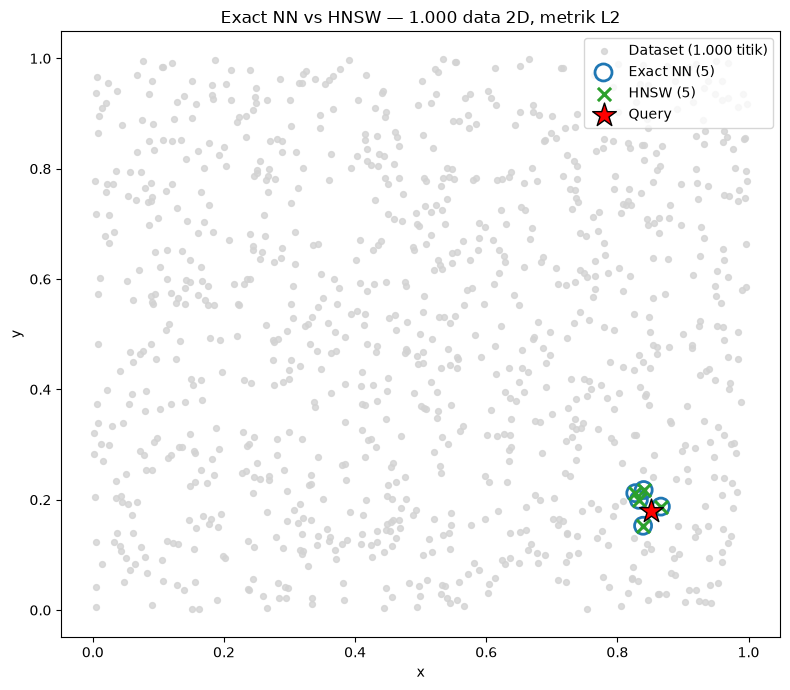

Exact NN : [662, 50, 984, 481, 993]
HNSW     : [662, 50, 984, 481, 993]
Recall@5 : 100%


In [7]:
X_plot, Q_plot = generate_data(1_000, 2, n_queries=1)
query_plot = Q_plot[0]

plot_exact_ids, _, _ = benchmark_exact(X_plot, Q_plot, K, "l2")
plot_index, _ = build_hnsw(X_plot, "l2")
plot_hnsw_ids, _, _ = benchmark_hnsw(plot_index, Q_plot, K)

fig_scatter, ax = plt.subplots(figsize=(8, 7))
ax.scatter(X_plot[:, 0], X_plot[:, 1], s=18, c="lightgray", alpha=0.8,
           label="Dataset (1.000 titik)")
ax.scatter(X_plot[plot_exact_ids[0], 0], X_plot[plot_exact_ids[0], 1],
           s=150, facecolors="none", edgecolors="tab:blue", linewidths=2,
           label="Exact NN (5)")
ax.scatter(X_plot[plot_hnsw_ids[0], 0], X_plot[plot_hnsw_ids[0], 1],
           s=90, marker="x", c="tab:green", linewidths=2.2,
           label="HNSW (5)")
ax.scatter(query_plot[0], query_plot[1], marker="*", s=320, c="red",
           edgecolor="black", zorder=5, label="Query")
ax.set_title("Exact NN vs HNSW — 1.000 data 2D, metrik L2")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

print("Exact NN :", plot_exact_ids[0].tolist())
print("HNSW     :", plot_hnsw_ids[0].tolist())
print("Recall@5 :", f"{recall_at_k(plot_exact_ids[0], plot_hnsw_ids[0]):.0%}")

### 6. Grafik waktu pencarian, percepatan, dan Recall@5

Sumbu waktu memakai skala logaritmik karena selisih waktu Exact dan HNSW pada 1 juta data sangat besar. Grafik recall memakai rentang 0–1; nilai 1 berarti lima tetangga yang ditemukan HNSW identik dengan Exact NN. Dua batang recall ditampilkan: **exact match** (indeks harus sama persis) dan **tie-aware** (jarak dalam toleransi `float32`).

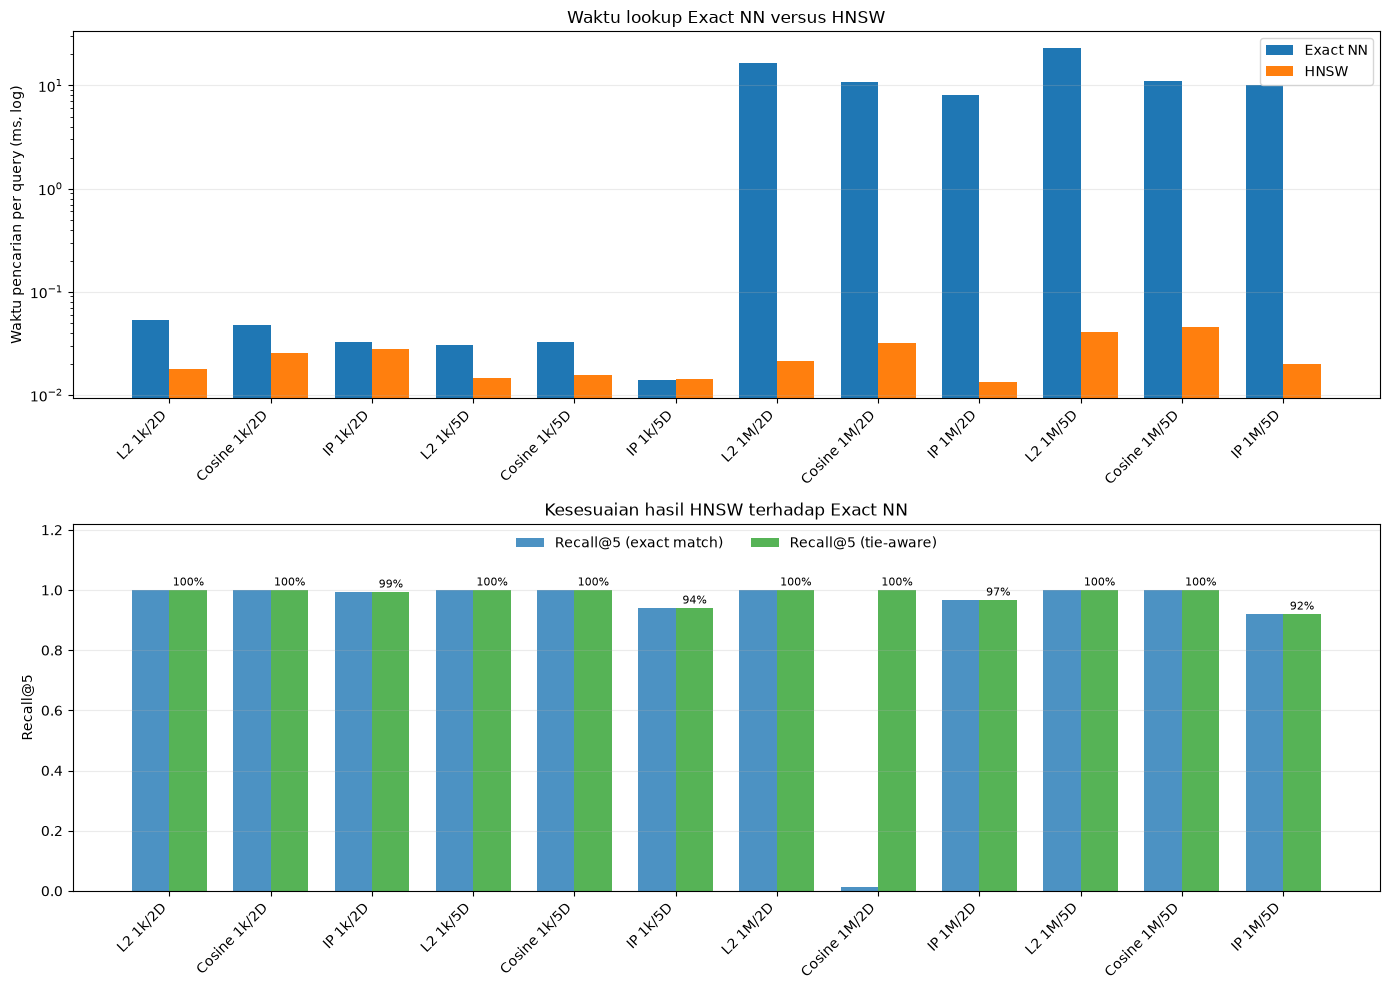

=== RINGKASAN ===
L2 (Euclidean)  |     1,000 | 2D | Exact    0.053 ms | HNSW   0.0180 ms |     3.0x | recall  100% | tie-aware  100% | build   0.03 s
Cosine          |     1,000 | 2D | Exact    0.048 ms | HNSW   0.0253 ms |     1.9x | recall  100% | tie-aware  100% | build   0.02 s
Inner Product   |     1,000 | 2D | Exact    0.033 ms | HNSW   0.0276 ms |     1.2x | recall   99% | tie-aware   99% | build   0.06 s
L2 (Euclidean)  |     1,000 | 5D | Exact    0.030 ms | HNSW   0.0147 ms |     2.1x | recall  100% | tie-aware  100% | build   0.01 s
Cosine          |     1,000 | 5D | Exact    0.033 ms | HNSW   0.0157 ms |     2.1x | recall  100% | tie-aware  100% | build   0.02 s
Inner Product   |     1,000 | 5D | Exact    0.014 ms | HNSW   0.0143 ms |     1.0x | recall   94% | tie-aware   94% | build   0.02 s
L2 (Euclidean)  | 1,000,000 | 2D | Exact   16.542 ms | HNSW   0.0212 ms |   781.0x | recall  100% | tie-aware  100% | build  13.42 s
Cosine          | 1,000,000 | 2D | Exact   10.887 m

In [8]:
short_metric = {
    "L2 (Euclidean)": "L2",
    "Cosine": "Cosine",
    "Inner Product": "IP",
}
labels = [
    f"{short_metric[r['Metrik']]} "
    f"{'1k' if r['Jumlah data'] == 1_000 else '1M'}/{r['Dimensi']}D"
    for _, r in df_hasil.iterrows()
]
positions = np.arange(len(df_hasil))
width = 0.37

fig_waktu, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].bar(positions - width / 2, df_hasil["Waktu Exact (ms)"], width,
            label="Exact NN")
axes[0].bar(positions + width / 2, df_hasil["Waktu HNSW (ms)"], width,
            label="HNSW")
axes[0].set_yscale("log")
axes[0].set_ylabel("Waktu pencarian per query (ms, log)")
axes[0].set_title("Waktu lookup Exact NN versus HNSW")
axes[0].set_xticks(positions, labels, rotation=45, ha="right")
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend()

axes[1].bar(positions - width / 2, df_hasil["Recall@5"], width,
            color="tab:blue", alpha=0.8, label="Recall@5 (exact match)")
axes[1].bar(positions + width / 2, df_hasil["Recall@5 (tie-aware)"], width,
            color="tab:green", alpha=0.8, label="Recall@5 (tie-aware)")
axes[1].set_ylim(0, 1.22)
axes[1].set_ylabel("Recall@5")
axes[1].set_title("Kesesuaian hasil HNSW terhadap Exact NN")
axes[1].set_xticks(positions, labels, rotation=45, ha="right")
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(loc="upper center", ncol=2, frameon=False)
for x, value in zip(positions, df_hasil["Recall@5 (tie-aware)"]):
    axes[1].text(x + width / 2, value + 0.015, f"{value:.0%}",
                 ha="center", fontsize=8)

plt.tight_layout()
plt.show()

print("=== RINGKASAN ===")
for _, r in df_hasil.iterrows():
    print(
        f"{r['Metrik']:15s} | {r['Jumlah data']:>9,} | {r['Dimensi']}D | "
        f"Exact {r['Waktu Exact (ms)']:8.3f} ms | "
        f"HNSW {r['Waktu HNSW (ms)']:8.4f} ms | "
        f"{r['Percepatan (x)']:7.1f}x | recall {r['Recall@5']:5.0%} | "
        f"tie-aware {r['Recall@5 (tie-aware)']:5.0%} | "
        f"build {r['Build index (s)']:6.2f} s"
    )

### 7. Ringkasan pengaruh jumlah data dan dimensi

Tabel berikut merata-ratakan ketiga metrik untuk melihat pola umum. Perhatikan perubahan waktu Exact saat data bertambah dari 1.000 ke 1.000.000, serta perubahan Recall@5 ketika dimensi naik dari 2D ke 5D.

In [9]:
ringkas = (
    df_hasil.groupby(["Jumlah data", "Dimensi"], as_index=False)
    .agg(
        Exact_ms=("Waktu Exact (ms)", "mean"),
        HNSW_ms=("Waktu HNSW (ms)", "mean"),
        Speedup=("Percepatan (x)", "mean"),
        Recall=("Recall@5", "mean"),
        TieRecall=("Recall@5 (tie-aware)", "mean"),
        Build_s=("Build index (s)", "mean"),
    )
)
ringkas["Jumlah data"] = ringkas["Jumlah data"].map(lambda v: f"{v:,}")
ringkas = ringkas.rename(columns={
    "Exact_ms": "Rata-rata Exact (ms)",
    "HNSW_ms": "Rata-rata HNSW (ms)",
    "Speedup": "Rata-rata percepatan (x)",
    "Recall": "Rata-rata Recall@5",
    "TieRecall": "Rata-rata Recall@5 (tie-aware)",
    "Build_s": "Rata-rata build (s)",
})
ringkas["Rata-rata Exact (ms)"] = ringkas["Rata-rata Exact (ms)"].map(lambda v: f"{v:.3f}")
ringkas["Rata-rata HNSW (ms)"] = ringkas["Rata-rata HNSW (ms)"].map(lambda v: f"{v:.4f}")
ringkas["Rata-rata percepatan (x)"] = ringkas["Rata-rata percepatan (x)"].map(lambda v: f"{v:.1f}")
ringkas["Rata-rata Recall@5"] = ringkas["Rata-rata Recall@5"].map(lambda v: f"{v:.1%}")
ringkas["Rata-rata Recall@5 (tie-aware)"] = ringkas["Rata-rata Recall@5 (tie-aware)"].map(lambda v: f"{v:.1%}")
ringkas["Rata-rata build (s)"] = ringkas["Rata-rata build (s)"].map(lambda v: f"{v:.2f}")

display(ringkas)

# Rasio waktu Exact 1 juta terhadap 1.000 data (rata-rata tiga metrik).
for dim in [2, 5]:
    kecil = df_hasil.loc[
        (df_hasil["Jumlah data"] == 1_000) & (df_hasil["Dimensi"] == dim),
        "Waktu Exact (ms)",
    ].mean()
    besar = df_hasil.loc[
        (df_hasil["Jumlah data"] == 1_000_000) & (df_hasil["Dimensi"] == dim),
        "Waktu Exact (ms)",
    ].mean()
    print(f"Exact {dim}D: 1 juta / 1.000 data = {besar / kecil:.1f}x lebih lambat")

,Jumlah data,Dimensi,Rata-rata Exact (ms),Rata-rata HNSW (ms),Rata-rata percepatan (x),Rata-rata Recall@5,Rata-rata Recall@5 (tie-aware),Rata-rata build (s)
0,"1,000",2,0.045,0.0236,2.0,99.8%,99.8%,0.04
1,"1,000",5,0.026,0.0149,1.7,98.0%,98.0%,0.02
2,"1,000,000",2,11.860,0.0221,577.1,66.0%,98.9%,17.53
3,"1,000,000",5,14.745,0.0355,436.1,97.3%,97.3%,21.96


Exact 2D: 1 juta / 1.000 data = 265.5x lebih lambat
Exact 5D: 1 juta / 1.000 data = 575.2x lebih lambat


### 8. Penyimpanan hasil eksperimen

Tabel disimpan sebagai CSV dan grafik sebagai PNG agar dapat dilampirkan pada laporan. Di Google Colab, file muncul di panel **Files**; di lingkungan lokal, file ditulis ke direktori kerja notebook.

In [10]:
df_hasil.to_csv("JS06_Praktikum3_Hasil_Percobaan.csv", index=False)
fig_scatter.savefig("JS06_Praktikum3_Visualisasi_2D.png", dpi=150,
                    bbox_inches="tight")
fig_waktu.savefig("JS06_Praktikum3_Waktu_Recall.png", dpi=150,
                  bbox_inches="tight")

print("File yang dihasilkan:")
print("- JS06_Praktikum3_Hasil_Percobaan.csv")
print("- JS06_Praktikum3_Visualisasi_2D.png")
print("- JS06_Praktikum3_Waktu_Recall.png")

File yang dihasilkan:
- JS06_Praktikum3_Hasil_Percobaan.csv
- JS06_Praktikum3_Visualisasi_2D.png
- JS06_Praktikum3_Waktu_Recall.png


### 9. Analisis dan kesimpulan

> Angka pada bagian ini merujuk pada tabel hasil eksekusi terakhir di notebook. Waktu benchmark sangat dipengaruhi beban CPU dan kondisi mesin; jika sel dijalankan ulang, nilai absolut dapat berubah, tetapi pola umumnya tetap.

**1. Exact NN sebagai patokan.** Exact NN memeriksa seluruh dataset, sehingga hasilnya selalu menjadi *ground truth*. Pada percobaan ini waktu Exact untuk 1 juta data berkisar **8,2–23,1 ms** per query, sedangkan pada 1.000 data hanya sekitar **0,014–0,053 ms**. Pemindaian seluruh vektor tetap menjadi bottleneck utama saat koleksi membesar.

**2. HNSW jauh lebih cepat pada data besar.** Pada 1 juta data, HNSW hanya membutuhkan sekitar **0,013–0,046 ms** per query. Percepatan rata-rata ketiga metrik adalah **577x pada 2D** dan **436x pada 5D**, dengan rentang **245x–781x**. Sebaliknya, pada 1.000 data percepatan rata-rata hanya **2,0x (2D)** dan **1,7x (5D)**; satu konfigurasi (Inner Product 5D) berada di sekitar **1,0x** karena waktu Exact sudah sangat kecil dan ada *overhead* pemanggilan Python serta penelusuran graf.

**3. Recall@5.** L2 mencapai **100%** pada semua kombinasi. Cosine juga **100%**, kecuali satu kasus yang dijelaskan di poin 4. Inner Product sedikit lebih rendah, yaitu **97% (1 juta, 2D)** dan **92% (1 juta, 5D)**, serta **99% (1.000, 2D)** dan **94% (1.000, 5D)**. Artinya, penghematan waktu HNSW tidak serta-merta mengorbankan kualitas hasil; penurunan recall terutama terjadi pada metrik yang geometrinya kurang cocok untuk graf HNSW.

**4. Anomali Cosine 2D dan tie pada `float32`.** Pada 1 juta titik 2D, jarak Cosine sangat rapat: untuk query pertama, ada **1.441 titik** yang jaraknya berada dalam `d5 + 1e-6`. Banyak nilai bahkan membulat menjadi 0 pada `float32`, sehingga lima tetangga “terdekat” tidak lagi unik. Akibatnya `Recall@5` berbasis kecocokan indeks hanya **1%**, tetapi `Recall@5 (tie-aware)` menjadi **100%** dan `Top-1 (tie-aware)` juga **100%**. Angka 1% bukan berarti HNSW gagal menemukan tetangga yang jauh; ia menemukan titik-titik yang jaraknya praktis sama, hanya berbeda pada pemilihan indeks di antara *tie*. Pada 5D, jarak Cosine lebih terpisah sehingga recall exact-match kembali **100%**.

**5. Pengaruh jumlah data.** Dari 1.000 ke 1.000.000 data, waktu Exact rata-rata meningkat **265,5x (2D)** dan **575,2x (5D)**. Waktu HNSW tetap berada pada orde **0,01–0,05 ms** untuk kedua ukuran data. Pola ini konsisten dengan pencarian graf yang mendekati logaritmik, sehingga HNSW cocok untuk koleksi vektor besar. Namun, waktu **build** HNSW naik dari **0,01–0,06 s** pada 1.000 data menjadi **13,4–22,3 s** pada 1 juta data; biaya *offline* ini perlu diperhitungkan.

**6. Pengaruh dimensi.** Pada 1 juta data, waktu Exact rata-rata naik dari **11,86 ms (2D)** menjadi **14,74 ms (5D)**, sedangkan HNSW naik dari **0,0221 ms** menjadi **0,0355 ms**. Kenaikan dimensi juga menurunkan recall Inner Product dari **97% ke 92%**. Pada dimensi yang lebih tinggi, *curse of dimensionality* membuat jarak antarvektor semakin seragam sehingga ANN lebih sulit mencapai recall tinggi; gejala ini belum terlalu kuat pada 5D, tetapi akan lebih terasa pada dimensi puluhan atau ratusan.

**7. Perbedaan metrik.** L2 mengukur jarak posisi, Cosine membandingkan arah setelah normalisasi, dan Inner Product mempertimbangkan panjang vektor. Karena definisinya berbeda, tetangga terdekatnya juga dapat berbeda. Inner Product **bukan metrik jarak sejati** (tidak memenuhi ketaksamaan segitiga), sehingga HNSW `space='ip'` memiliki recall lebih rendah daripada L2/Cosine pada data yang tidak dinormalisasi. Untuk data yang mementingkan kemiripan arah (misalnya embedding teks), Cosine biasanya lebih tepat; untuk data yang panjang vektornya bermakna, Inner Product dapat lebih sesuai.

**8. Tradeoff parameter dan keterbatasan.** Percobaan ini memakai `M=16`, `ef_construction=100`, dan `ef=50` untuk semua baris. `ef` mengontrol kompromi *speed versus accuracy*: nilai kecil mempercepat pencarian tetapi menurunkan recall; nilai besar meningkatkan recall tetapi menambah latensi. `M` dan `ef_construction` terutama memengaruhi kualitas graf dan waktu build. Karena parameter ini tidak divariasikan, hasil belum tentu optimal untuk setiap dataset; sweep `ef` dan `M` dapat dilakukan pada percobaan lanjutan.

**9. Kapan memakai HNSW?** HNSW cocok untuk pencarian *real-time* pada dataset besar yang jarang berubah. Jika data sering diperbarui dalam jumlah besar, biaya pembangunan ulang indeks perlu dipertimbangkan. Untuk dataset kecil atau kebutuhan hasil yang benar-benar eksak, brute force masih sederhana dan kompetitif.

> **Kesimpulan akhir:** HNSW memberikan percepatan besar pada data 1 juta, yaitu sekitar **245x–781x** lebih cepat daripada Exact NN. `Recall@5` mencapai **100%** untuk L2 dan Cosine 5D, serta **92–99%** untuk Inner Product. Cosine 2D 1 juta menunjukkan **1%** exact-match akibat *tie* numerik, tetapi **100%** setelah diukur secara *tie-aware*. Keunggulan HNSW mengecil pada dataset 1.000 titik, dan kualitasnya bergantung pada metrik, dimensi, serta parameter `M`, `ef_construction`, dan `ef`.

### Referensi

- [hnswlib — GitHub (nmslib/hnswlib)](https://github.com/nmslib/hnswlib): dokumentasi API `hnswlib.Index`, parameter `M`, `ef_construction`, dan `ef`.
- [hnswlib — PyPI](https://pypi.org/project/hnswlib/): instalasi dan catatan kompatibilitas.
- Malkov, Y. A., & Yashunin, D. A. (2020). *Efficient and Robust Approximate Nearest Neighbor Search Using Hierarchical Navigable Small World Graphs*. IEEE TPAMI, 42(4), 824–836.
- [scikit-learn — Nearest Neighbors](https://scikit-learn.org/stable/modules/neighbors.html): dasar pencarian tetangga terdekat dan metrik jarak.